In [19]:
%pip install imbalanced-learn

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [20]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer

from sklearn.metrics import(
    confusion_matrix,
    classification_report,
    roc_curve,
    roc_auc_score,
    ConfusionMatrixDisplay
)

from sklearn.ensemble import RandomForestClassifier

from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE

from xgboost import XGBClassifier


In [21]:
import pandas as pd

url = "https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/master/data/Telco-Customer-Churn.csv"

data = pd.read_csv(url)

data.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [22]:
df=data.copy()

In [23]:
print(df.shape)
print(df.columns)
df.info()

(7043, 21)
Index(['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents',
       'tenure', 'PhoneService', 'MultipleLines', 'InternetService',
       'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport',
       'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling',
       'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn'],
      dtype='str')
<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str   

In [24]:
df.isnull().sum()

customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

In [25]:
df.duplicated().sum()

np.int64(0)

In [26]:
# Convert TotalCharges to numeric
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")

# Fill any missing values created during conversion
df["TotalCharges"] = df["TotalCharges"].fillna(df["TotalCharges"].median())

# Verify
df["TotalCharges"].isnull().sum()

np.int64(0)

In [27]:
df.drop("customerID", axis=1, inplace=True)

df.head()

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,No
2,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [28]:
df["Churn"] = df["Churn"].map({
    "No": 0,
    "Yes": 1
})

df["Churn"].value_counts()

Churn
0    5174
1    1869
Name: count, dtype: int64

In [29]:
print(df["Churn"].value_counts())
print(df["Churn"].isnull().sum())

Churn
0    5174
1    1869
Name: count, dtype: int64
0


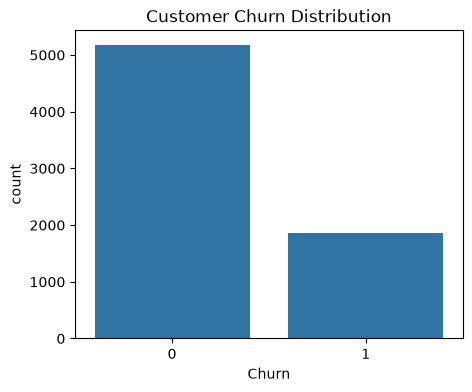

Churn
0    0.73463
1    0.26537
Name: proportion, dtype: float64


In [30]:
plt.figure(figsize=(5,4))

sns.countplot(x="Churn", data=df)

plt.title("Customer Churn Distribution")

plt.show()

print(df["Churn"].value_counts(normalize=True))

In [31]:
from sklearn.model_selection import train_test_split

X = df.drop("Churn", axis=1)
y = df["Churn"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("X_train:", X_train.shape)
print("X_test :", X_test.shape)
print("y_train:", y_train.shape)
print("y_test :", y_test.shape)

X_train: (5634, 19)
X_test : (1409, 19)
y_train: (5634,)
y_test : (1409,)


In [35]:
cat_cols=X_train.select_dtypes(include="object").columns.tolist()
num_cols=X_train.select_dtypes(exclude="object").columns.tolist()

print("\nNumerical Columns:",len(cat_cols))
print(cat_cols)

print("Numerical Columns:",len(num_cols))
print(num_cols)



Numerical Columns: 15
['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']
Numerical Columns: 4
['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']


C:\Users\keert\AppData\Local\Temp\ipykernel_15416\137139739.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_cols=X_train.select_dtypes(include="object").columns.tolist()


## Preprocessing Pipeline

In [36]:
# Numerical pipeline
numeric_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="median"))
])

# Categorical pipeline
categorical_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Combine both pipelines
preprocessor = ColumnTransformer([
    ("num", numeric_transformer, num_cols),
    ("cat", categorical_transformer, cat_cols)
])

print("Preprocessor created successfully!")

Preprocessor created successfully!


## Random Forest Pipeline

In [37]:
rf_pipeline = ImbPipeline([
    ("preprocessor", preprocessor),

    ("smote", SMOTE(random_state=42)),

    ("classifier", RandomForestClassifier(
        n_estimators=300,
        max_depth=12,
        random_state=42
    ))
])

In [38]:
rf_pipeline.fit(X_train, y_train)

,steps,"[('preprocessor', ...), ('smote', ...), ...]"
,transform_input,None
,memory,None
,verbose,False
Name,Type,Value
classes_,"ndarray[int64](2,)","[0,1]"
feature_names_in_,"ndarray[object](19,)","['gender','SeniorCitizen','Partner',...,'PaymentMethod','MonthlyCharges', 'TotalCharges']"
n_features_in_,int,19
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3


In [39]:
rf_pred = rf_pipeline.predict(X_test)

rf_prob = rf_pipeline.predict_proba(X_test)[:, 1]

### ROC-AUC Score

In [40]:
rf_auc = roc_auc_score(y_test, rf_prob)

print("ROC-AUC Score:", round(rf_auc, 4))

ROC-AUC Score: 0.8329


### Classification Report

In [41]:
from sklearn.metrics import classification_report

print(classification_report(y_test, rf_pred))

              precision    recall  f1-score   support

           0       0.85      0.85      0.85      1035
           1       0.59      0.59      0.59       374

    accuracy                           0.78      1409
   macro avg       0.72      0.72      0.72      1409
weighted avg       0.78      0.78      0.78      1409



### Confusion Matrix

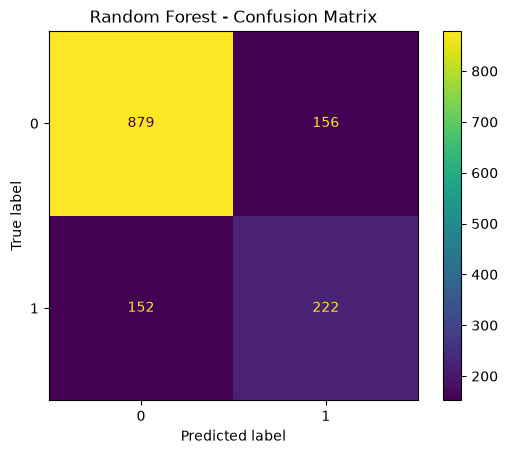

In [42]:
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

ConfusionMatrixDisplay.from_predictions(y_test, rf_pred)

plt.title("Random Forest - Confusion Matrix")
plt.show()

## XGBoost Pipeline

In [45]:
xgb_pipeline = ImbPipeline([
    ("preprocessor", preprocessor),

    ("smote", SMOTE(random_state=42)),

    ("classifier", XGBClassifier(
        n_estimators=300,
        learning_rate=0.05,
        max_depth=5,
        subsample=0.8,
        colsample_bytree=0.8,
        eval_metric="logloss",
        random_state=42
    ))
])

In [46]:
xgb_pipeline.fit(X_train, y_train)

,steps,"[('preprocessor', ...), ('smote', ...), ...]"
,transform_input,None
,memory,None
,verbose,False
Name,Type,Value
classes_,"ndarray[int64](2,)","[0,1]"
feature_names_in_,"ndarray[object](19,)","['gender','SeniorCitizen','Partner',...,'PaymentMethod','MonthlyCharges', 'TotalCharges']"
n_features_in_,int,19
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3


In [47]:
xgb_pred = xgb_pipeline.predict(X_test)

xgb_prob = xgb_pipeline.predict_proba(X_test)[:,1]

## ROC-AUC Score

In [48]:
xgb_auc = roc_auc_score(y_test, xgb_prob)

print("XGBoost ROC-AUC:", round(xgb_auc,4))

XGBoost ROC-AUC: 0.8382


In [50]:
print(classification_report(y_test, xgb_pred))

              precision    recall  f1-score   support

           0       0.85      0.88      0.86      1035
           1       0.62      0.56      0.59       374

    accuracy                           0.79      1409
   macro avg       0.73      0.72      0.72      1409
weighted avg       0.79      0.79      0.79      1409



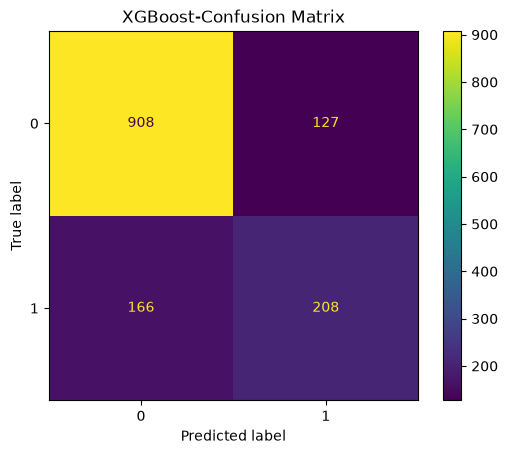

In [51]:
ConfusionMatrixDisplay.from_predictions(y_test,xgb_pred)
plt.title("XGBoost-Confusion Matrix")
plt.show()

In [53]:
comparison={
    "Random Forest": round(rf_auc,4),
    "XGBoost": round(xgb_auc,4)
}
print(comparison)

{'Random Forest': 0.8329, 'XGBoost': 0.8382}


### ROC Curves

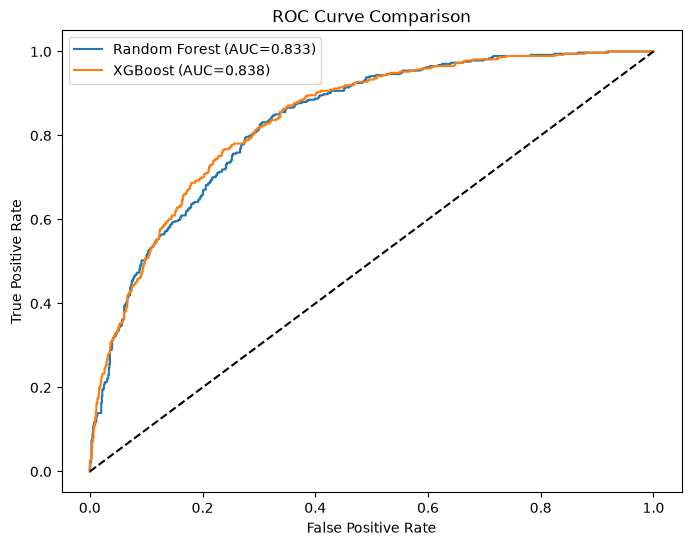

In [54]:
rf_fpr,rf_tpr,_=roc_curve(y_test,rf_prob)
xgb_fpr,xgb_tpr,_=roc_curve(y_test,xgb_prob)
plt.figure(figsize=(8,6))
plt.plot(rf_fpr,rf_tpr,
         label=f"Random Forest (AUC={rf_auc:.3f})")
plt.plot(xgb_fpr,xgb_tpr,
         label=f"XGBoost (AUC={xgb_auc:.3f})")
plt.plot([0,1],[0,1],'k--')

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve Comparison")

plt.legend()

plt.show()


## Feature Importance Plot

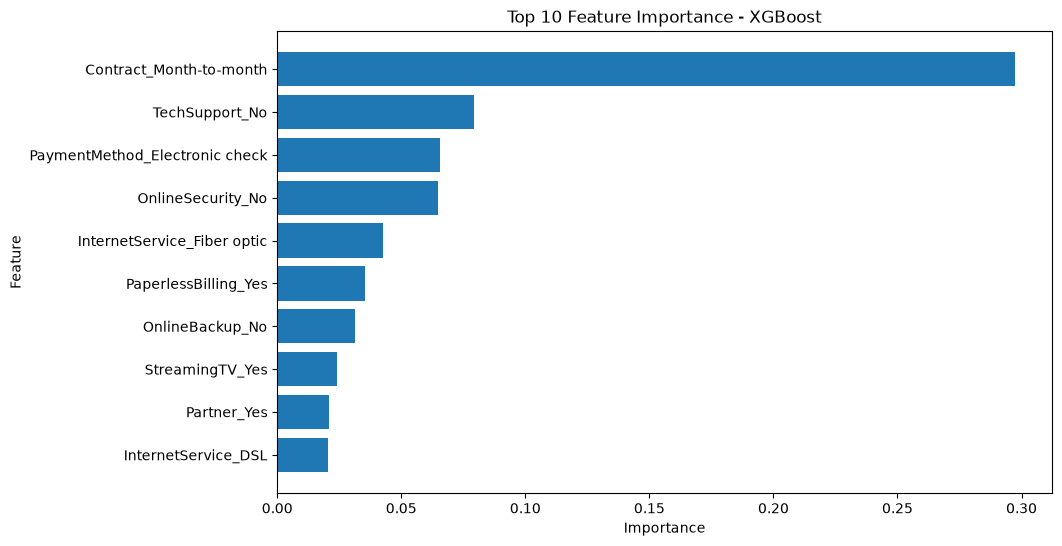

In [55]:
encoder = xgb_pipeline.named_steps["preprocessor"] \
    .named_transformers_["cat"] \
    .named_steps["encoder"]

cat_features = encoder.get_feature_names_out(cat_cols)

feature_names = list(num_cols) + list(cat_features)

importance = xgb_pipeline.named_steps["classifier"].feature_importances_

importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importance
}).sort_values(by="Importance", ascending=False)

top10 = importance_df.head(10)

plt.figure(figsize=(10,6))
plt.barh(top10["Feature"], top10["Importance"])
plt.gca().invert_yaxis()
plt.xlabel("Importance")
plt.ylabel("Feature")
plt.title("Top 10 Feature Importance - XGBoost")
plt.show()

# Business Insights

The machine learning models provided valuable insights into the factors influencing customer churn in the telecom industry.

- **Customers with Month-to-Month contracts have the highest churn risk.** Encouraging these customers to switch to long-term contracts through discounts or loyalty benefits may improve customer retention.

- **Customers without Tech Support and Online Security services are more likely to leave.** Promoting these value-added services can enhance customer satisfaction and reduce churn.

- **Customers using Electronic Check as their payment method show a higher tendency to churn.** The company can encourage customers to use more convenient payment options such as automatic bank payments or credit card billing.

- **Fiber Optic Internet customers exhibit a relatively higher churn rate.** The company should investigate service quality, pricing, and customer support for these customers to improve retention.

- **The predictive model enables early identification of customers who are likely to churn.** This allows the business to implement proactive retention strategies such as personalized offers, targeted promotions, loyalty rewards, and improved customer support before customers decide to leave.

- **Among the evaluated models, XGBoost achieved the highest ROC-AUC score (0.838), outperforming Random Forest (0.833).** Therefore, XGBoost is the preferred model for customer churn prediction due to its better predictive performance.

Overall, the developed churn prediction model can support data-driven decision-making by helping telecom companies identify high-risk customers, reduce customer attrition, improve retention strategies, and increase long-term business profitability.

# Conclusion

In this project, a predictive customer churn classification model was developed using the IBM Telco Customer Churn dataset. The dataset was preprocessed by handling missing values, converting data types, encoding categorical variables using OneHotEncoder, and addressing class imbalance with SMOTE. Two ensemble machine learning algorithms, **Random Forest** and **XGBoost**, were trained and evaluated to identify customers who are likely to discontinue the telecom service.

The performance of both models was assessed using ROC-AUC, confusion matrices, classification reports, and ROC curves. The **Random Forest** model achieved a **ROC-AUC score of 0.833**, while the **XGBoost** model achieved a slightly better **ROC-AUC score of 0.838**, making it the best-performing model for this dataset. Both models successfully exceeded the target ROC-AUC score of **0.80**, demonstrating strong predictive capability.

Feature importance analysis revealed that **Month-to-Month Contract**, **Lack of Tech Support**, **Electronic Check Payment Method**, **Lack of Online Security**, and **Fiber Optic Internet Service** were the most influential factors associated with customer churn. These insights can help telecom companies identify customers at higher risk of leaving and implement targeted retention strategies such as promoting long-term contracts, improving customer support services, and offering personalized retention plans.

Overall, this project demonstrates the complete machine learning workflow, including data preprocessing, feature engineering, handling class imbalance, model training, evaluation, visualization, and interpretation. The developed model provides a practical solution for predicting customer churn and can support data-driven business decisions to improve customer retention and reduce revenue loss.